In [51]:
import polars as pl
import polars.selectors as cs
import leafmap.maplibregl as leafmap
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path
import seaborn as sns
import sys

In [52]:
DATA_DIR = Path.cwd().parent / "data"
ICP_DIR = DATA_DIR / "ICP"
ICP_OBSERVATIONS = ICP_DIR / "axel/cpf-level2_cleaned.parquet"

In [53]:
full_df = pl.read_parquet(ICP_OBSERVATIONS)
full_num_df = full_df.select(cs.numeric())



print(len(full_df.columns))
print(full_num_df.columns)

110
['survey_year', 'country_code', 'tree_species_code', 'plot_code', 'diameter_start', 'diameter_end', 'period_duration_d', 'period_duration_y', 'growth', 'growth_rate', 'growth_rel', 'growth_rate_rel', 'diameter_method_code_start', 'diameter_method_code_end', 'removal_code_end', 'plot_latitude', 'plot_longitude', 'plot_slope', 'plot_altitude', 'num_defoliation_obs', 'defoliation_mean', 'defoliation_min', 'defoliation_max', 'defoliation_median', 'defoliation_last', 'social_class_min', 'social_class_max', 'social_class_mode', 'social_class_last', 'num_deposition_obs', 'yearly_precip', 'dep_ph', 'dep_cond', 'dep_k', 'dep_ca', 'dep_mg', 'dep_na', 'dep_n_nh4', 'dep_cl', 'dep_n_no3', 'dep_s_so4', 'dep_alk', 'dep_n_tot', 'dep_doc', 'dep_al', 'dep_mn', 'dep_fe', 'dep_p_po4', 'dep_cu', 'dep_zn', 'dep_hg', 'dep_pb', 'dep_co', 'dep_mo', 'dep_ni', 'dep_cd', 'dep_s_tot', 'dep_c_tot', 'dep_n_org', 'dep_p_tot', 'dep_cr', 'dep_n_no2', 'dep_hco3', 'dep_don', 'num_soil_obs', 'ss_ph', 'ss_cond', 'ss_k'

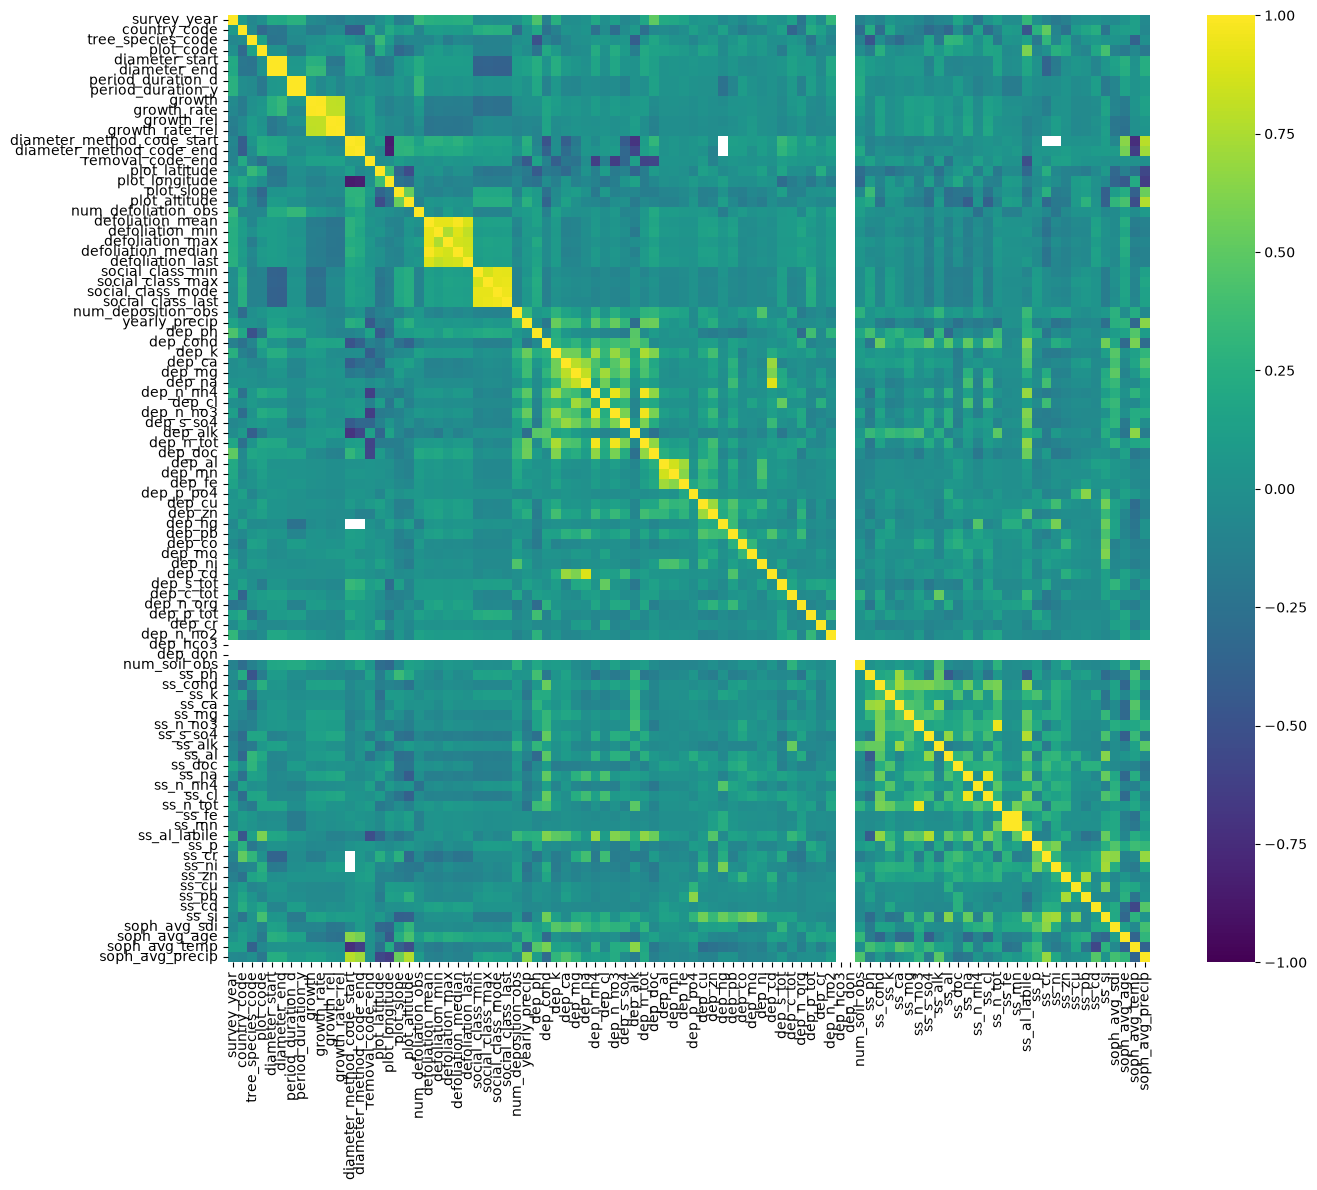

In [54]:

cols = full_num_df.columns

corr = np.array([
    [
        full_num_df.select(pl.corr(a, b)).item()
        for b in cols
    ]
    for a in cols
])


plt.figure(figsize=(14, 12))
sns.heatmap(
    corr,
    xticklabels=full_num_df.columns,
    yticklabels=full_num_df.columns,
    cmap="viridis",
    vmin=-1,
    vmax=1,
    center=0,
)
plt.tight_layout()
plt.show()

In [55]:
import pandas as pd

corr_table = pd.DataFrame(
    corr,
    index=full_num_df.columns,
    columns=full_num_df.columns,
)

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(
        corr_table["growth_rate"]
        .drop("growth_rate")
        .sort_values(key=lambda s: s.abs(), ascending=False)
        .round(3).to_frame().transpose()
    )

,growth,growth_rate_rel,growth_rel,diameter_end,social_class_min,social_class_mode,social_class_last,diameter_start,social_class_max,dep_cond,soph_avg_age,country_code,defoliation_mean,ss_si,defoliation_median,defoliation_max,ss_cond,defoliation_last,defoliation_min,ss_cr,ss_na,ss_mg,ss_s_so4,ss_cl,soph_avg_precip,removal_code_end,plot_longitude,ss_n_no3,ss_n_tot,dep_n_org,dep_n_no3,num_soil_obs,dep_n_nh4,dep_k,dep_n_tot,soph_avg_sdi,ss_al,survey_year,plot_altitude,dep_alk,plot_latitude,num_defoliation_obs,dep_mg,dep_cr,ss_p,diameter_method_code_end,plot_slope,period_duration_y,period_duration_d,plot_code,ss_alk,dep_doc,ss_ph,dep_s_so4,ss_pb,ss_cu,dep_s_tot,ss_ca,dep_c_tot,dep_n_no2,dep_mo,dep_ca,dep_p_tot,ss_cd,ss_al_labile,dep_pb,ss_n_nh4,dep_cl,soph_avg_temp,num_deposition_obs,dep_co,ss_zn,dep_p_po4,ss_ni,ss_doc,dep_cu,dep_hg,dep_zn,ss_mn,dep_na,ss_fe,diameter_method_code_start,yearly_precip,dep_mn,tree_species_code,dep_ni,dep_ph,dep_al,dep_fe,dep_cd,ss_k,dep_hco3,dep_don
growth_rate,0.991,0.812,0.809,0.325,-0.274,-0.262,-0.261,0.255,-0.24,0.179,-0.178,-0.165,-0.164,0.162,-0.16,-0.157,0.151,-0.149,-0.148,-0.147,0.143,0.142,0.14,0.138,0.132,0.126,-0.119,0.11,0.099,0.098,0.098,0.097,0.095,0.093,0.09,-0.09,0.084,-0.076,-0.075,0.073,-0.068,0.061,0.06,-0.06,-0.06,0.059,-0.057,-0.056,-0.056,0.056,0.055,-0.052,-0.051,0.05,-0.05,-0.048,-0.047,0.046,0.045,0.044,0.043,0.042,-0.042,-0.038,-0.034,0.034,-0.029,0.029,0.029,-0.027,0.027,0.025,-0.021,0.016,-0.016,0.013,-0.012,-0.011,0.01,0.008,0.007,0.007,0.007,0.006,0.002,0.001,-0.001,0.001,-0.0,0.0,-0.0,NaN,NaN


In [56]:
# Intuitive + corr selection of the columns to keep

id_cols = [
    "tree_id",
    "plot_id",
    "tree_number",
    "plot_code",
    "tree_species_code",
    "country_code"
]

plot_cols = [
    "plot_altitude",
    "plot_slope",
    "plot_orientation",
    "plot_latitude",
    "plot_longitude",
]

soph_cols = [
    "soph_avg_age",
    "soph_avg_sdi",
]

defoliaton_cols = [
    "defoliation_mean",
    "defoliation_median",
    "defoliation_last",

]

dep_cols = [
    "dep_n_tot",
    "dep_n_no3",
    "dep_nh4",
    "dep_cond"
]

growth_cols = [
    "growth_rate",
    "diameter_start",
    "diameter_end",
    "growth_rel",
    "growth_rate_rel",
    "growth"
]

others_cols = [
    "specie",
    "social_class_mode",
    "yearly_precip",
]

In [57]:
print(full_df["period_end"].max())

2025-11-13 00:00:00


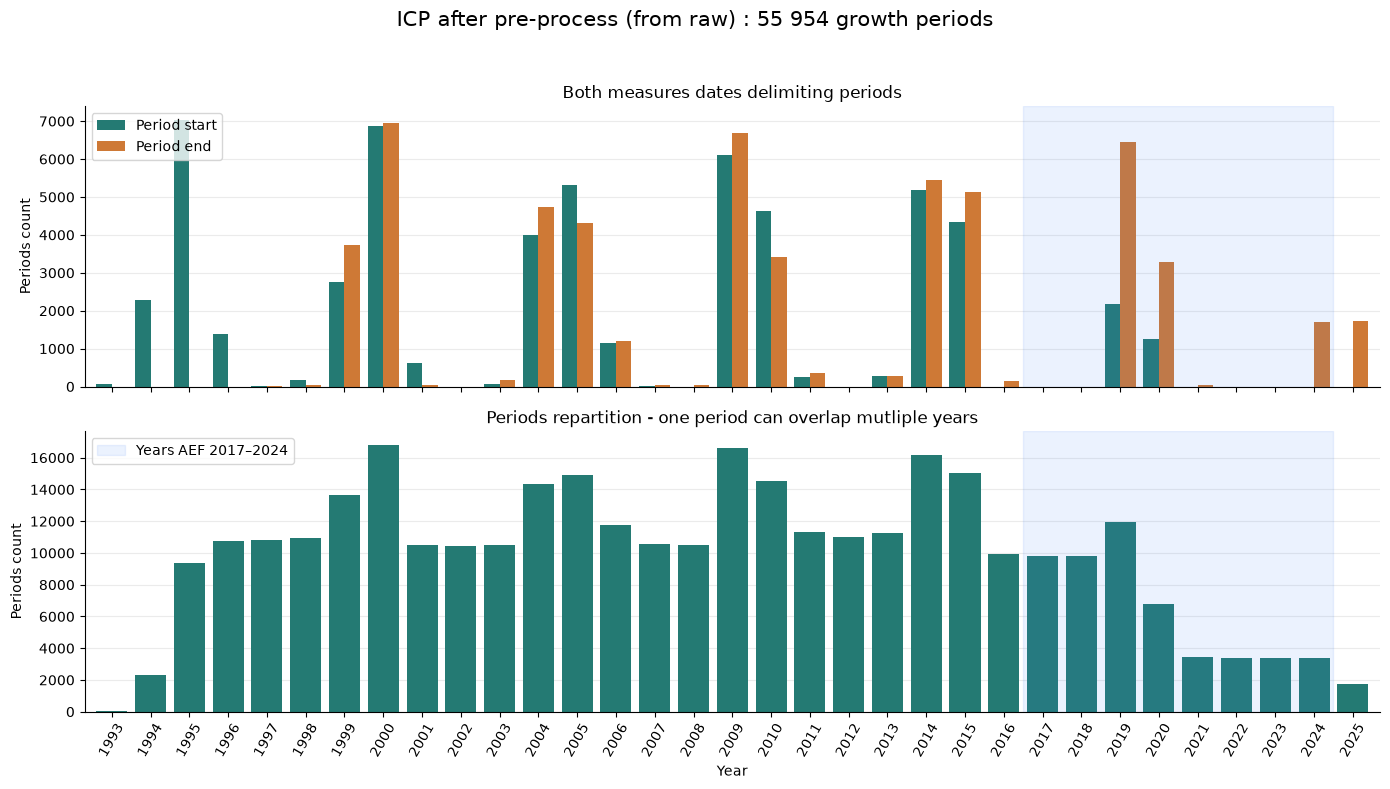

In [58]:
# Periods remaining after pre-processing
periods = full_df.select("period_start", "period_end").drop_nulls()
years = list(range(
    periods["period_start"].min().year,
    periods["period_end"].max().year + 1,
))

starts = (
    periods.group_by(pl.col("period_start").dt.year().alias("year"))
    .len().sort("year")
)
ends = (
    periods.group_by(pl.col("period_end").dt.year().alias("year"))
    .len().sort("year")
)
coverage = (
    periods.select(pl.int_ranges(
        pl.col("period_start").dt.year(),
        pl.col("period_end").dt.year() + 1,
    ).alias("year"))
    .explode("year")
    .group_by("year").len().sort("year")
)

# No observations -> zeros
start_counts = dict(starts.iter_rows())
end_counts = dict(ends.iter_rows())
coverage_counts = dict(coverage.iter_rows())
temporal_distribution = pl.DataFrame({
    "year": years,
    "period_starts": [start_counts.get(y, 0) for y in years],
    "period_ends": [end_counts.get(y, 0) for y in years],
    "overlapping_periods": [coverage_counts.get(y, 0) for y in years],
})

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
x = np.array(years)
axes[0].bar(x - 0.2, temporal_distribution["period_starts"].to_numpy(),
            width=0.4, color="#247a73", label="Period start")
axes[0].bar(x + 0.2, temporal_distribution["period_ends"].to_numpy(),
            width=0.4, color="#ce7936", label="Period end")
axes[0].set_title("Both measures dates delimiting periods")
axes[0].set_ylabel("Periods count")
axes[0].legend(loc="upper left")

axes[1].bar(x, temporal_distribution["overlapping_periods"].to_numpy(),
            color="#247a73", width=0.8)
axes[1].set_title("Periods repartition - one period can overlap mutliple years")
axes[1].set_ylabel("Periods count")
axes[1].set_xlabel("Year")
for ax in axes:
    ax.axvspan(2016.5, 2024.5, color="#3b82f6", alpha=0.10,
               label="Years AEF 2017–2024")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(loc="upper left")
axes[1].set_xticks(years)
axes[1].tick_params(axis="x", rotation=60)
axes[1].set_xlim(years[0] - 0.7, years[-1] + 0.7)
fig.suptitle(
    f"ICP after pre-process (from raw) : {periods.height:,} growth periods".replace(",", " "),
    fontsize=15,
)
fig.tight_layout(rect=(0, 0, 1, 0.95))

figure_path = ICP_DIR / "axel" / "temporal_distribution_from_raw.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()


In [59]:
# load parquet file as dataframe
df = pl.read_parquet(
    ICP_OBSERVATIONS, columns=["plot_id", "plot_latitude", "plot_longitude", "growth_rate"]
)

# Group by plot (id, lat, long) -> mean growth per year
plots = df.group_by("plot_id", "plot_latitude", "plot_longitude").agg(
    pl.len().alias("n_periods"),
    pl.col("growth_rate").mean().alias("mean_growth_cm_year"),
)

print(plots.shape)
print(plots)

(465, 5)
shape: (465, 5)
┌─────────┬───────────────┬────────────────┬───────────┬─────────────────────┐
│ plot_id ┆ plot_latitude ┆ plot_longitude ┆ n_periods ┆ mean_growth_cm_year │
│ ---     ┆ ---           ┆ ---            ┆ ---       ┆ ---                 │
│ str     ┆ i64           ┆ i64            ┆ u32       ┆ f64                 │
╞═════════╪═══════════════╪════════════════╪═══════════╪═════════════════════╡
│ 54.0207 ┆ 491000        ┆ 201400         ┆ 218       ┆ 0.098771            │
│ 04.0906 ┆ 480700        ┆ 115500         ┆ 316       ┆ 0.300184            │
│ 51.0001 ┆ 475300        ┆ 195700         ┆ 564       ┆ 0.216331            │
│ 04.0862 ┆ 484500        ┆ 92500          ┆ 43        ┆ 0.384916            │
│ 13.5802 ┆ 563800        ┆ 153700         ┆ 34        ┆ 0.443039            │
│ …       ┆ …             ┆ …              ┆ …         ┆ …                   │
│ 04.0301 ┆ 525000        ┆ 101500         ┆ 212       ┆ 0.212505            │
│ 14.0011 ┆ 475200        ┆

In [60]:
# Transform degrees to decimal -> fit the leafmap and EarthEngine coord. system
def dms_to_decimal(val):
    degs, rem = divmod(abs(val), 10_000)
    mins, secs = divmod(rem, 100)
    sign = -1 if val < 0 else 1
    return sign * (degs + mins / 60 + secs / 3600)

In [61]:
# Setup the features for leafmap
features = []

for row in plots.iter_rows(named=True):
    lon = dms_to_decimal(row["plot_longitude"])
    lat = dms_to_decimal(row["plot_latitude"])

    # dict with leafmap format
    features.append(
        {
            "type": "Feature",
            "geometry": {"type": "Point", "coordinates": [lon, lat]},
            "properties": {
                "plot_id": row["plot_id"],
                "n_periods": row["n_periods"],
                "mean_growth_cm_year": row["mean_growth_cm_year"],
            },
        }
    )

In [64]:
# Create and display the map
m = leafmap.Map(height="650px")
m.add_basemap("USGS.Imagery")
m.add_geojson(
    {"type": "FeatureCollection", "features": features},
    name="ICP plots",
    layer_type="circle",
    paint={
        "circle-radius": 5,
        "circle-stroke-color": "#ffffff",
        "circle-stroke-width": 1,
        "circle-color": [
            "interpolate",
            ["linear"],
            ["get", "mean_growth_cm_year"],
            0.15,
            "red",
            0.28,
            "violet",
            0.48,
            "blue",
        ],
    },
)
m.add_legend(
    title="Diameter mean growth",
    legend_dict={
        "0.15 cm/year": "#ff0000",
        "0.28 cm/year": "#ee82ee",
        "0.48 cm/year": "#0000ff",
    },
    shape_type="circle",
    position="bottom-right",
)

m
m

Html(children=[<leafmap.maplibregl.Map object at 0x00000276FE1D10F0>, Card(children=[Btn(children=[Icon(childr…